# Lecture 17 – Data 100, Spring 2026

[Acknowledgments Page](https://ds100.org/acknowledgements/)

In [1]:
import json
import seaborn as sns
import polars as pl
import matplotlib.pyplot as plt
import numpy as np

import warnings
warnings.filterwarnings('ignore')


from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import root_mean_squared_error

sns.set()

In this lecture, we will work with the `vehicles` dataset.

In [2]:
vehicles = pl.from_pandas(sns.load_dataset("mpg")).rename({"horsepower": "hp"}).drop_nulls().sort("hp", maintain_order=True)
vehicles.head()

mpg,cylinders,displacement,hp,weight,acceleration,model_year,origin,name
f64,i64,f64,f64,i64,f64,i64,str,str
26.0,4,97.0,46.0,1835,20.5,70,"""europe""","""volkswagen 1131 deluxe sedan"""
26.0,4,97.0,46.0,1950,21.0,73,"""europe""","""volkswagen super beetle"""
43.1,4,90.0,48.0,1985,21.5,78,"""europe""","""volkswagen rabbit custom diese…"
44.3,4,90.0,48.0,2085,21.7,80,"""europe""","""vw rabbit c (diesel)"""
43.4,4,90.0,48.0,2335,23.7,80,"""europe""","""vw dasher (diesel)"""


We will attempt to predict a car's `"mpg"` from transformations of its `"hp"`.

In [3]:
X = vehicles.select("hp")
X = X.with_columns((pl.col("hp")**2).alias("hp^2"))
X = X.with_columns((pl.col("hp")**3).alias("hp^3"))
X = X.with_columns((pl.col("hp")**4).alias("hp^4"))

Y = vehicles["mpg"]

In [4]:
X.head()

hp,hp^2,hp^3,hp^4
f64,f64,f64,f64
46.0,2116.0,97336.0,4.477456e6
46.0,2116.0,97336.0,4.477456e6
48.0,2304.0,110592.0,5.308416e6
48.0,2304.0,110592.0,5.308416e6
48.0,2304.0,110592.0,5.308416e6


## Test Set

To perform a train-test split, we can use the `train_test_split` function of the `sklearn.model_selection` module.

In [5]:
from sklearn.model_selection import train_test_split

# `test_size` specifies the proportion of the full dataset that should be allocated to testing.
# `random_state` makes our results reproducible for educational purposes.
# shuffle is True by default and randomizes the data before splitting.

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2, 
    random_state=100, 
    shuffle=True
)

print(f"Size of full dataset: {X.shape[0]} points")
print(f"Size of training set: {X_train.shape[0]} points")
print(f"Size of test set: {X_test.shape[0]} points")

Size of full dataset: 392 points
Size of training set: 313 points
Size of test set: 79 points


We then fit the model using the training set...

In [6]:
import sklearn.linear_model as lm

model = lm.LinearRegression()

model.fit(X_train, Y_train)

model.coef_

array([-8.14508303e-01,  4.46081359e-03, -1.15685106e-05,  1.29445334e-08])

...and evaluate its performance by making predictions on the test set. Notice that the model performs more poorly on the test data it did not encounter during training.

In [7]:
from sklearn.metrics import mean_squared_error

train_error = mean_squared_error(Y_train, model.predict(X_train))
test_error = mean_squared_error(Y_test, model.predict(X_test))

print(f"Training error: {train_error}")
print(f"Test error: {test_error}")

Training error: 18.00424324304199
Test error: 23.27046886820572


## Validation Set

To estimate model performance on unseen data, and then *use* this information to finetune the model, we introduce a validation set. You can imagine this as us splitting the training set into a validation set and a "mini" training set.

In [8]:
# Split X_train further into X_train_mini and X_val.
X_train_mini, X_val, Y_train_mini, Y_val = train_test_split(X_train, Y_train, test_size=0.2, random_state=100)

print(f"Size of original training set: {X_train.shape[0]} points")
print(f"Size of mini training set: {X_train_mini.shape[0]} points")
print(f"Size of validation set: {X_val.shape[0]} points")

Size of original training set: 313 points
Size of mini training set: 250 points
Size of validation set: 63 points


In the cell below, we repeat the experiment from Lecture 14: fit several models of increasing complexity, then compute their errors. Here, we find the model's errors on the **validation set** to understand how model complexity influences performance on unseen data.

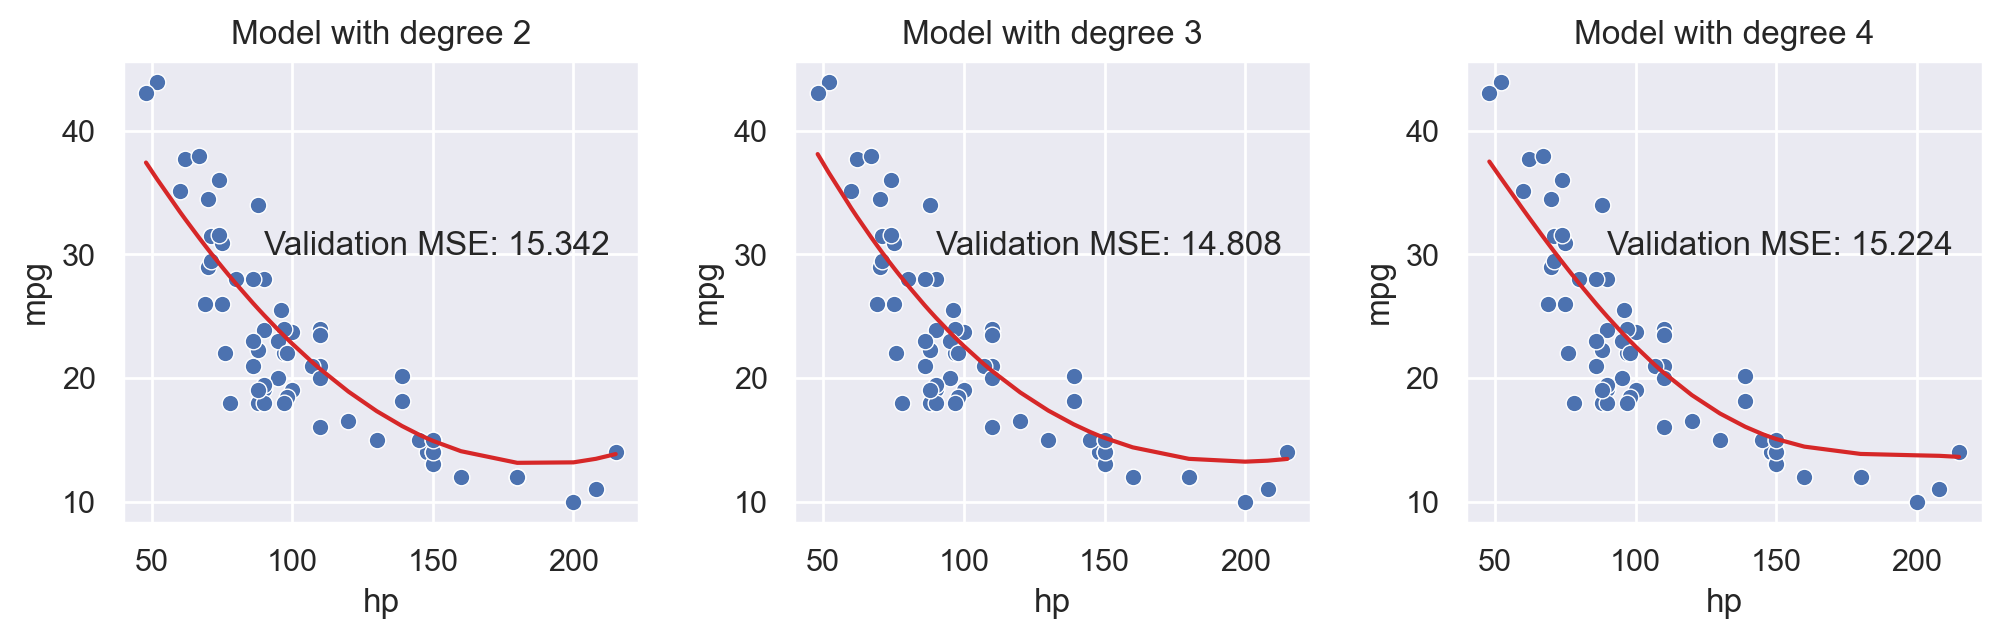

In [9]:
fig, ax = plt.subplots(1, 3, dpi=200, figsize=(12, 3))

# iterate over polynomial orders 2, 3, and 4
for order in [2, 3, 4]:
    model = lm.LinearRegression()
    model.fit(X_train_mini[:, :order], Y_train_mini)
    val_predictions = model.predict(X_val[:, :order])
    
    output = X_val[:, :order]
    output = output.with_columns(y_hat=pl.Series(val_predictions))
    output = output.sort("hp")
    
    ax[order-2].scatter(X_val["hp"], Y_val, edgecolor="white", lw=0.5)
    ax[order-2].plot(output["hp"], output["y_hat"], "tab:red")
    ax[order-2].set_title(f"Model with degree {order}")
    ax[order-2].set_xlabel("hp")
    ax[order-2].set_ylabel("mpg")
    ax[order-2].annotate(f"Validation MSE: {np.round(mean_squared_error(Y_val, val_predictions), 3)}", (90, 30))

plt.subplots_adjust(wspace=0.3);

Let's repeat this process:

1. Fit an degree-x model to the mini training set
2. Evaluate the fitted model's MSE when making predictions on the validation set

We use the model's performance on the validation set as a guide to selecting the best combination of features. We are not limited in the number of times we use the validation set – we just never use this set to fit the model.

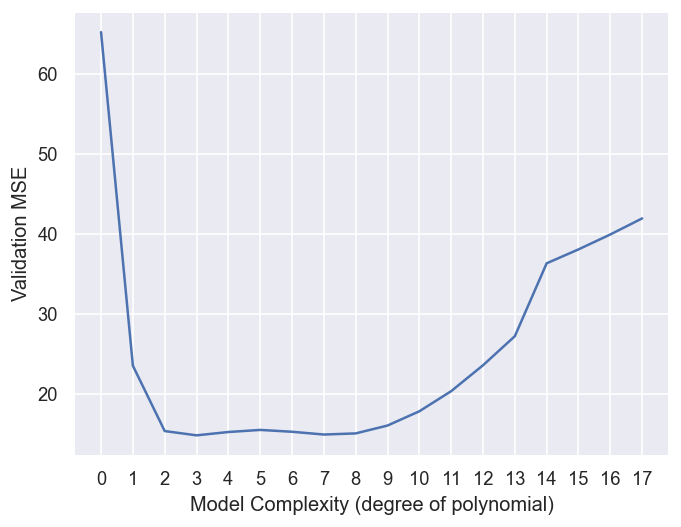

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

def fit_model_dataset(degree):
    pipelined_model = Pipeline([
        ('polynomial_transformation', PolynomialFeatures(degree)),
        ('linear_regression', lm.LinearRegression())    
    ])

    pipelined_model.fit(X_train_mini.select("hp"), Y_train_mini)
    return mean_squared_error(Y_val, pipelined_model.predict(X_val.select("hp")))

errors = [fit_model_dataset(degree) for degree in range(0, 18)]
MSEs_and_k = pl.DataFrame({"k": range(0, 18), "MSE": errors})

plt.figure(dpi=120)
plt.plot(range(0, 18), errors)
plt.xlabel("Model Complexity (degree of polynomial)")
plt.ylabel("Validation MSE")
plt.xticks(range(0, 18));

In [11]:
MSEs_and_k.rename({"k": "Degree"})

Degree,MSE
i64,f64
0,65.171445
1,23.503836
2,15.342167
3,14.807811
4,15.224005
…,…
13,27.190448
14,36.296031
15,38.033905


From this **model selection** process, the validation error bottoms out at degree 3 and is nearly as low all the way through degree 8. Any of those degrees is a reasonable choice; below, we build a model with degree 8.

In [12]:
print(f'Polynomial degree with lowest validation error: {MSEs_and_k.sort("MSE").head(1)["k"].to_numpy()}')

Polynomial degree with lowest validation error: [3]


After this choice has been finalized, and we are completely finished with the model design process, we finally assess model performance on the test set. We typically use the entire training set (both the "mini" training set and validation set) to fit the final model.

In [13]:
# Update our training and test sets to include all polynomial features between 5 and 9
for degree in range(5, 9):
    X_train = X_train.with_columns((pl.col("hp")**degree).alias(f"hp^{degree}"))
    X_test = X_test.with_columns((pl.col("hp")**degree).alias(f"hp^{degree}"))

final_model = lm.LinearRegression()
final_model.fit(X_train, Y_train)

print(f"Test MSE of final model: {mean_squared_error(Y_test, final_model.predict(X_test))}")

Test MSE of final model: 22.03838963831279


## Cross-Validation

The validation set gave us an opportunity to understand how the model performs on a **single** set of unseen data. The specific validation set we drew was fixed – we used the same validation points every time.

It's possible that we may have, by random chance, selected a set of validation points that was *not* representative of other unseen data that the model might encounter (for example, if we happened to have selected all outlying data points for the validation set).

Different train/validation splits lead to different validation errors:

In [14]:
for i in range(1, 4):
    X_train_mini, X_val, Y_train_mini, Y_val = train_test_split(X_train, Y_train, test_size=0.2)
    model = lm.LinearRegression()
    model.fit(X_train_mini, Y_train_mini)
    y_hat = model.predict(X_val)
    print(f"Val error from train/validation split #{i}: {mean_squared_error(y_hat, Y_val)}")

Val error from train/validation split #1: 17.8962841147823
Val error from train/validation split #2: 24.015873264518138
Val error from train/validation split #3: 21.44560072863981


To apply cross-validation, we use the `KFold` class of `sklearn.model_selection`. `KFold` will return the indices of each cross-validation fold. Then, we iterate over each of these folds to designate it as the validation set, while training the model on the remaining folds.

In [15]:
from sklearn.model_selection import KFold
np.random.seed(25) # Ensures reproducibility of this notebook

# n_splits sets the number of folds to create
kf = KFold(n_splits=5, shuffle=True)
validation_errors = []

for train_idx, valid_idx in kf.split(X_train):
    # Split the data
    split_X_train, split_X_valid = X_train[train_idx], X_train[valid_idx]
    split_Y_train, split_Y_valid = Y_train[train_idx], Y_train[valid_idx]

    # Fit the model on the training split
    model.fit(split_X_train, split_Y_train)

    error = mean_squared_error(model.predict(split_X_valid), split_Y_valid)

    validation_errors.append(error)

print(f"Cross-validation error: {np.mean(validation_errors)}")

Cross-validation error: 18.65000800957946


## Regularization

### L1 (LASSO) Regularization

To apply L1 regularization, we use the `Lasso` model class of `sklearn`. `Lasso` functions just like `LinearRegression`. The difference is that now the model will apply a *regularization penalty*. We specify the strength of regularization using the `alpha` parameter, which is equivalent to $\frac{1}{\lambda}$ from our objective function formulation.

In [16]:
import sklearn.linear_model as lm

lasso_model = lm.Lasso(alpha=0.1) # In sklearn, alpha represents the lambda hyperparameter
lasso_model.fit(X_train, Y_train) 

lasso_model.coef_

array([-5.64165156e-01,  1.45465684e-03,  2.77092942e-06, -2.44300630e-09,
       -3.39290802e-11, -1.09815580e-13, -2.06671895e-17,  2.10910783e-18])

To increase the strength of regularization (decrease model complexity), we increase the $\lambda$ hyperparameter by changing `alpha`.

In [17]:
lasso_model_large_lambda = lm.Lasso(alpha=10)
lasso_model_large_lambda.fit(X_train, Y_train) 

lasso_model_large_lambda.coef_

array([-0.00000000e+00, -3.51295993e-03,  1.41852444e-05,  1.71408584e-08,
       -2.96533086e-11, -2.27103481e-13, -5.49668638e-16,  8.34000795e-19])

Notice that these model coefficients are very small (some are effectively 0). This reflects L1 regularization's tendency to set the parameters of unimportant features to 0. We can use this in **feature selection**.

The features in our dataset are on wildly different numerical scales. To see this, compare the values of `hp` to the values of `hp^8`.

In [18]:
X_train.head()

hp,hp^2,hp^3,hp^4,hp^5,hp^6,hp^7,hp^8
f64,f64,f64,f64,f64,f64,f64,f64
150.0,22500.0,3.375e6,5.0625e8,7.5938e10,1.1391e13,1.7086e15,2.5629e17
150.0,22500.0,3.375e6,5.0625e8,7.5938e10,1.1391e13,1.7086e15,2.5629e17
158.0,24964.0,3.944312e6,6.23201296e8,9.8466e10,1.5558e13,2.4581e15,3.8838e17
180.0,32400.0,5.832e6,1.0498e9,1.8896e11,3.4012e13,6.1222e15,1.1020e18
137.0,18769.0,2.571353e6,3.52275361e8,4.8262e10,6.6119e12,9.0582e14,1.2410e17


In order for the feature `hp` to contribute in any meaningful way to the model, LASSO is "forced" to allocate disproportionately much of its parameter "budget" towards assigning a large value to the model parameter for `hp`. Notice how the parameter for `hp` is much, much greater in magnitude than the parameter for `hp^8`.

In [19]:
pl.DataFrame({"Feature": X_train.columns, "Parameter": lasso_model.coef_})

Feature,Parameter
str,f64
"""hp""",-0.564165
"""hp^2""",0.001455
"""hp^3""",0.000003
"""hp^4""",-2.4430e-9
"""hp^5""",-3.3929e-11
"""hp^6""",-1.0982e-13
"""hp^7""",-2.0667e-17
"""hp^8""",2.1091e-18


We typically **scale** data before regularization such that all features are measured on the same numeric scale. One way to do this is by **standardizing** the data such that it has mean 0 and standard deviation 1.

In [20]:
# Center the data to have mean 0
X_train_centered = X_train.with_columns(pl.all() - pl.all().mean())

# Scale the centered data to have SD 1
X_train_standardized = X_train_centered.with_columns(pl.all() / pl.all().std())

X_train_standardized.head()

hp,hp^2,hp^3,hp^4,hp^5,hp^6,hp^7,hp^8
f64,f64,f64,f64,f64,f64,f64,f64
1.135297,0.984896,0.775312,0.553371,0.354272,0.194283,0.074957,-0.009505
1.135297,0.984896,0.775312,0.553371,0.354272,0.194283,0.074957,-0.009505
1.339125,1.231354,1.041813,0.815907,0.594634,0.402529,0.248159,0.130244
1.899651,1.975127,1.925462,1.773459,1.560109,1.324804,1.094889,0.88523
0.804077,0.611709,0.399115,0.207724,0.058991,-0.044537,-0.110553,-0.149359


When we re-fit a LASSO model, the coefficients are no longer as uneven in magnitude as they were before.

In [21]:
lasso_model_scaled = lm.Lasso(alpha=0.1)
lasso_model_scaled.fit(X_train_standardized, Y_train)
lasso_model_scaled.coef_

array([-9.55353509,  0.        ,  0.        ,  3.85579464,  0.        ,
        0.        ,  0.        ,  0.        ])

### L2 (Ridge) Regression

We perform ridge regression using `sklearn`'s `Ridge` class.

In [22]:
ridge_model = lm.Ridge(alpha=0.1)
ridge_model.fit(X_train_standardized, Y_train)

ridge_model.coef_

array([-18.69683767,   5.34645891,  10.30717468,   4.08284065,
        -3.39116085,  -6.26844835,  -3.04309438,   5.41826634])

## Example: predicting how much bleaching occurs in coral reefs

![Infographic by NOAA titled 'Coral Bleaching'. Healthy coral: Coral and algae depend on each other to survive. Stressed coral: If stressed, algae leaves the coral. Beached Coral: Coral is left bleached and vulnerable. Change in ocean temperature, runoff and pollution, overexposure to sunlight, and extreme low tides cause coral bleaching. ](https://oceanservice.noaa.gov/facts/coralbleaching-large.jpg)

## Data

In [23]:
reefs = pl.read_csv('reef.csv', null_values='NA', infer_schema_length=None)

# Only do predictions for reefs with bleaching
reefs = reefs.filter(pl.col('Average_bleaching') > 0)

# This tells Polars to show all the columns of the dataframe, just within this block
with pl.Config(tbl_cols=-1):
    display(reefs.sample(3))

Reef.ID,Reef.Name,Ocean,Country,State.Province.Island,City.Town,Year,Date,Depth,Organism.Code,S1,S2,S3,S4,Errors.,What.errors.,Average_bleaching,ClimSST,Temperature_Kelvin,Temperature_Mean,Temperature_Minimum,Temperature_Maximum,Temperature_Kelvin_Standard_Deviation,Windspeed,SSTA,SSTA_Standard_Deviation,SSTA_Mean,SSTA_Minimum,SSTA_Maximum,SSTA_Frequency,SSTA_Frequency_Standard_Deviation,SSTA_FrequencyMax,SSTA_FrequencyMean,SSTA_DHW,SSTA_DHW_Standard_Deviation,SSTA_DHWMax,SSTA_DHWMean,TSA,TSA_Standard_Deviation,TSA_Minimum,TSA_Maximum,TSA_Mean,TSA_Frequency,TSA_Frequency_Standard_Deviation,TSA_FrequencyMax,TSA_FrequencyMean,TSA_DHW,TSA_DHW_Standard_Deviation,TSA_DHWMax,TSA_DHWMean,Region,Diversity,rate_of_SST_change,Longitude.Degrees,Latitude.Degrees
str,str,str,str,str,str,i64,str,f64,str,f64,f64,f64,f64,bool,str,f64,f64,f64,f64,f64,f64,f64,i64,f64,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,i64,f64,f64,f64
"""117.26.46.4E.7.0.13.4N""","""Mantabuan Channel""","""Pacific""","""Malaysia""","""Sabah""","""Mantabuan Banggi""",2013,"""2-Oct-13""",5.0,"""Bleaching (% of population)""",0.0,0.0,5.0,0.0,true,"""no site description""",1.25,301.88,302.89,302.01,297.82,305.12,1.26,4,0.21,0.85,0,-3.76,2.39,8.0,4.42,22.0,5.0,0.0,2.39,13.46,1.79,-0.1,1.26,-5.17,2.12,-0.97,1.0,2.0,10.0,1.0,0.0,1.33,8.43,0.64,"""ERG045""",567,0.012904,117.446222,7.003722
"""61.04W.13.51.5N""","""Rachette Point""","""Atlantic""","""St Lucia""",null,"""Soufriere""",2005,"""26-Oct-05""",5.0,"""Bleaching (% of population)""",35.0,50.0,50.0,35.0,false,null,42.5,262.15,301.353333,300.636667,297.27,304.013333,1.083333,7,-0.536667,0.71,0,-3.253333,2.413333,16.333333,4.64,24.666667,2.666667,8.193333,2.423333,17.46,1.013333,-0.7,1.083333,-4.776667,1.946667,-1.41,4.0,1.266667,5.666667,0.0,4.976667,0.836667,7.02,0.24,"""ERG138""",59,0.031136,-61.066667,13.858333
"""86.31.23W.15.56.16.6N""","""Cayo Timon""","""Atlantic""","""Honduras""","""Cayos Cochinos""","""Roatan""",2006,"""17-Mar-06""",6.0,"""Bleaching (% of population)""",2.0,0.0,10.0,20.0,false,null,8.0,301.22,300.02,301.21,297.63,305.55,1.31,6,-0.58,0.88,0,-3.16,3.47,16.0,5.05,23.0,6.0,2.38,3.0,17.42,2.12,-2.66,1.31,-5.04,2.86,-1.46,5.0,2.18,8.0,1.0,0.0,1.7,9.1,0.65,"""ERG136""",60,0.020682,-86.523056,15.937944


In [24]:
X_cols = ['Year', 'ClimSST', 'Temperature_Kelvin', 'SSTA', 'TSA', 'Diversity', 'rate_of_SST_change', 'Longitude.Degrees', 'Latitude.Degrees']
y_col = 'Average_bleaching'

# This is not generally a good practice: why not? What might you do instead?
reefs = reefs.drop_nulls(subset = X_cols + [y_col])

X = reefs.select(X_cols)
y = reefs[y_col]

X_train, X_val, y_train, y_val = train_test_split(X, y, random_state=12345)

In [25]:
X_train.head(3)

Year,ClimSST,Temperature_Kelvin,SSTA,TSA,Diversity,rate_of_SST_change,Longitude.Degrees,Latitude.Degrees
i64,f64,f64,f64,f64,i64,f64,f64,f64
2007,303.66,303.3,0.03,-0.36,503,0.015808,103.059111,5.771694
2009,301.74,301.84,0.64,-0.17,177,0.006111,-149.614167,-17.646333
2005,299.55,297.56,-0.07,-4.93,403,0.025429,146.507028,-18.668944


In [26]:
y_train.head(3)

Average_bleaching
f64
5.5
0.25
0.25


### Understanding LASSO

### For reference: using OLS

In [27]:
ols_model = LinearRegression()
ols_model.fit(X_train, y_train)
ols_model.coef_

array([-6.25639320e-02,  1.82012551e-02,  1.23674722e-01,  1.18936576e+00,
       -5.53738023e-02,  3.46258469e-03,  6.90185688e+01, -1.76952535e-02,
        3.07560345e-02])

In [28]:
print(root_mean_squared_error(ols_model.predict(X_val), y_val))

14.856922262418315


### First attempt: using LASSO

In [29]:
lasso_01 = Lasso(alpha=0.1)
lasso_01.fit(X_train, y_train)
lasso_01.coef_

array([-2.72286225e-02,  1.95566863e-02,  1.56136105e-02,  1.01898673e+00,
        0.00000000e+00,  9.27592534e-04,  0.00000000e+00, -1.42794196e-02,
        3.26018095e-02])

In [30]:
print(root_mean_squared_error(lasso_01.predict(X_val), y_val))

14.827256395703149


Let's decrease the budget (i.e., increase $\lambda$) and see what happens:

In [31]:
lasso_1 = Lasso(alpha=1)
lasso_1.fit(X_train, y_train)
lasso_1.coef_

array([-0.        ,  0.01179653,  0.        ,  0.        ,  0.        ,
        0.0009353 ,  0.        , -0.01440981,  0.03147831])

In [32]:
print(root_mean_squared_error(lasso_1.predict(X_val), y_val))

14.87740975764401


Now, some of the values we got back are 0! But this isn't a fair way to allocate our budget, because a small change in the $\theta$ value for `Diversity` (how many species are in the coral) can dramatically shift our output, just because the values in that column tend to be much larger. 

If we want to fairly allocate our budget across the different $\theta$ values, we need to **standardize** our inputs first: this means subtracting the mean and dividing by the standard deviation (more on these later).

You've seen these operations before in Data 8!

In [33]:
train_means = {c: X_train[c].mean() for c in X_train.columns}
train_stds = {c: X_train[c].std() for c in X_train.columns}

X_train_su = X_train.with_columns((pl.col(c) - train_means[c]) / train_stds[c] for c in X_train.columns)

# Be careful: make sure you understand why we're using the training set's mean
# and SD instead of X_val's or X's!
X_val_su = X_val.with_columns((pl.col(c) - train_means[c]) / train_stds[c] for c in X_val.columns)

In [34]:
lasso_01_su = Lasso(alpha=0.1)
lasso_01_su.fit(X_train_su, y_train)
lasso_01_su.coef_

array([-0.08029418,  0.1446849 ,  0.25917981,  0.75912157,  0.        ,
        0.        ,  0.39990794, -1.28557496,  0.38341893])

In [35]:
print(root_mean_squared_error(lasso_01_su.predict(X_val_su), y_val))

14.840484146060378


In [36]:
lasso_1_su = Lasso(alpha=1)
lasso_1_su.fit(X_train_su, y_train)
lasso_1_su.coef_

array([-0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
       -0.        ,  0.        , -0.57403383,  0.        ])

In [37]:
print(root_mean_squared_error(lasso_1_su.predict(X_val_su), y_val))

14.913928182965472


## How do different values of $\lambda$ (or `alpha` in `sklearn`) affect the results?

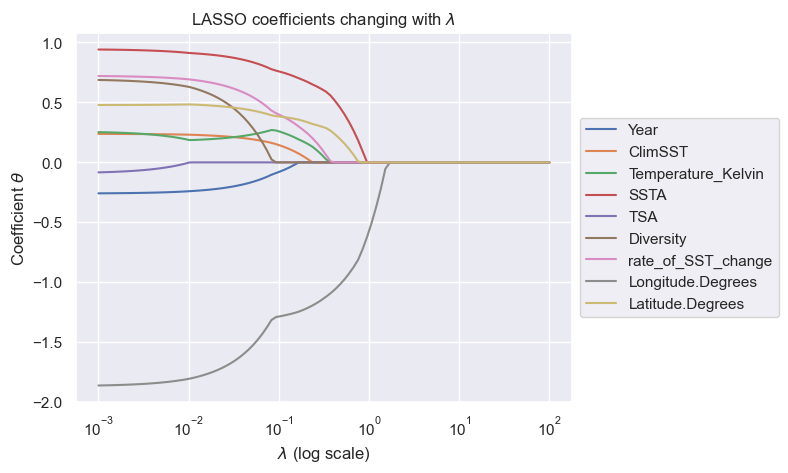

In [38]:
alphas = np.logspace(-3, 2, 100)
coeffs_lasso = []
lasso_val_errors = []
lasso_train_errors = []
for alpha in alphas:
    model = Lasso(alpha=alpha)
    model.fit(X_train_su, y_train)
    coeffs_lasso.append(model.coef_)
    lasso_val_errors.append(root_mean_squared_error(model.predict(X_val_su), y_val))
    lasso_train_errors.append(root_mean_squared_error(model.predict(X_train_su), y_train))
    

#coefficient_names = [col_map[c] for c in X_cols]
coefficient_names = X_cols

plt.plot(alphas, coeffs_lasso, label=coefficient_names)
plt.xlabel(r'$\lambda$ (log scale)')
plt.ylabel(r'Coefficient $\theta$')
plt.semilogx()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.title(r'LASSO coefficients changing with $\lambda$');

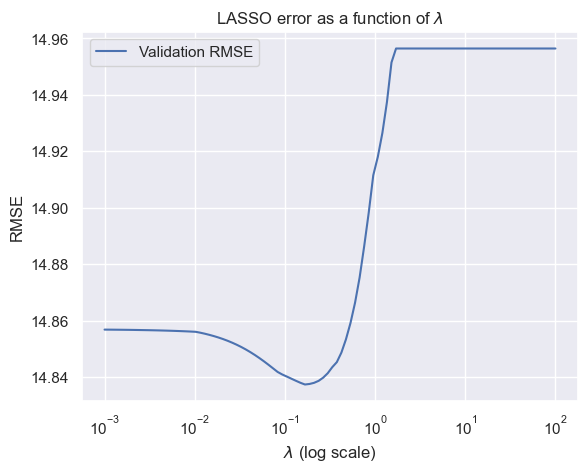

In [39]:
plt.plot(alphas, lasso_val_errors, label='Validation RMSE')
# Uncomment this line to see how the training error changes
# plt.plot(alphas, lasso_train_errors, label='Training RMSE')
plt.title('LASSO error as a function of $\lambda$')
plt.xlabel(r'$\lambda$ (log scale)')
plt.ylabel(r'RMSE');
plt.legend()
plt.semilogx();

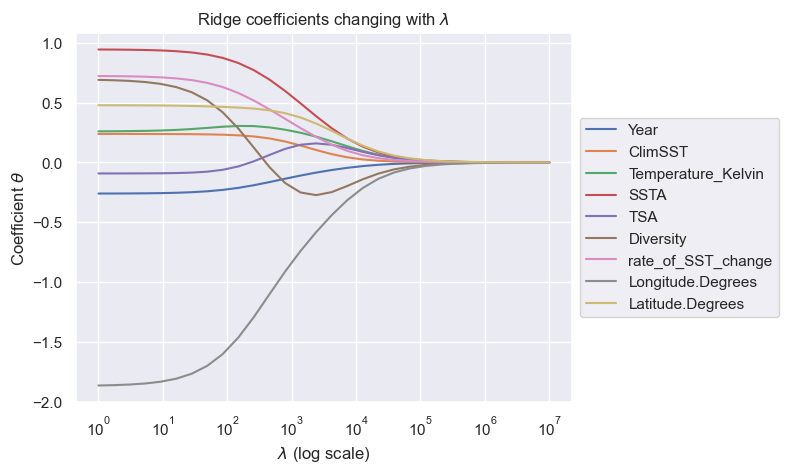

In [40]:
alphas = np.logspace(0, 7, 30)
coeffs_ridge = []
ridge_val_errors = []
for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train_su, y_train)
    coeffs_ridge.append(model.coef_)
    ridge_val_errors.append(root_mean_squared_error(model.predict(X_val_su), y_val))

#coefficient_names = [col_map[c] for c in X_cols]
coefficient_names = X_cols

plt.plot(alphas, coeffs_ridge, label=coefficient_names)
plt.xlabel(r'$\lambda$ (log scale)')
plt.ylabel(r'Coefficient $\theta$')
plt.semilogx()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.title(r'Ridge coefficients changing with $\lambda$');

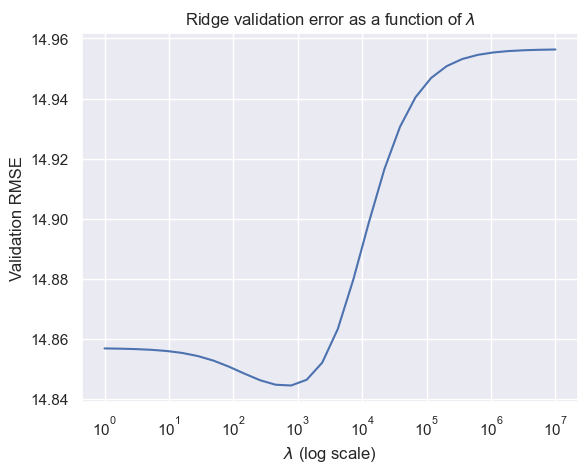

In [41]:
plt.plot(alphas, ridge_val_errors)
plt.title('Ridge validation error as a function of $\lambda$')
plt.xlabel(r'$\lambda$ (log scale)')
plt.ylabel(r'Validation RMSE');
plt.semilogx();

Bonus exercise: how would you modify the code above to use cross-validation error (CV error) instead of just validation set error?

## Bonus: using LASSO and Ridge with even more predictors and OHE in a scikit-learn `Pipeline`

In [42]:
X_cols = [
    'Ocean', 'Year', 'ClimSST', 'Temperature_Kelvin', 'SSTA', 'TSA', 'Diversity', 
    'rate_of_SST_change', 'Longitude.Degrees', 'Latitude.Degrees'
]
y_col = 'Average_bleaching'
numeric_X_cols = X_cols[1:]

In [43]:
X = reefs.select(X_cols)
y = reefs[y_col]

X_train, X_val, y_train, y_val = train_test_split(X, y, random_state=12345)

In [44]:
def make_linear_model_pipeline(model_type):

    pipeline = Pipeline([
        (
            "Feature Engineering", 
            ColumnTransformer(  
                [
                    ("OHE", OneHotEncoder(), ["Ocean"]),
                    ("Scale", StandardScaler(), numeric_X_cols),
                ], 
                remainder="passthrough")
        ),
        ("Model", model_type())
    ]) 
    return pipeline

In [45]:
alphas = np.logspace(-5, 1, 30)
coeffs_lasso_ohe = []
val_err_lasso_ohe = []
for alpha in alphas:
    pipe = make_linear_model_pipeline(Lasso)
    pipe.set_params(Model__alpha=alpha)
    pipe.fit(X_train, y_train)
    coeffs_lasso_ohe.append(pipe['Model'].coef_)
    val_err_lasso_ohe.append(root_mean_squared_error(pipe.predict(X_val), y_val))

coefficient_names = pipe[:-1].get_feature_names_out()

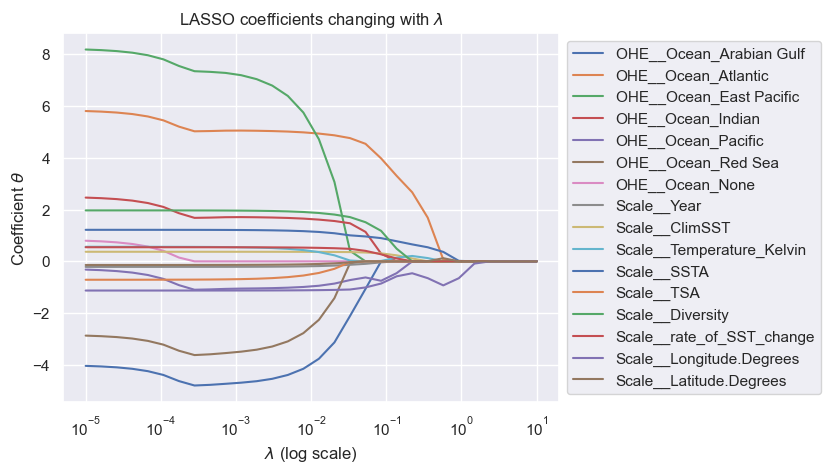

In [46]:
plt.plot(alphas, coeffs_lasso_ohe, label=coefficient_names)
plt.xlabel(r'$\lambda$ (log scale)')
plt.ylabel(r'Coefficient $\theta$')
plt.semilogx()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5));
plt.title(r'LASSO coefficients changing with $\lambda$');

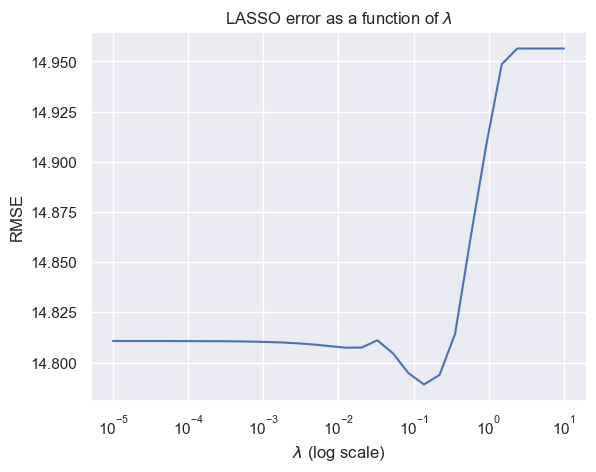

In [47]:
plt.plot(alphas, val_err_lasso_ohe, label='Validation RMSE')
plt.title('LASSO error as a function of $\lambda$')
plt.xlabel(r'$\lambda$ (log scale)')
plt.ylabel(r'RMSE');
plt.semilogx();

In [48]:
alphas = np.logspace(-1, 5, 30)
coeffs_ridge_ohe = []
val_err_ridge_ohe = []
for alpha in alphas:
    pipe = make_linear_model_pipeline(Ridge)
    pipe.set_params(Model__alpha=alpha)
    pipe.fit(X_train, y_train)
    coeffs_ridge_ohe.append(pipe['Model'].coef_)
    val_err_ridge_ohe.append(root_mean_squared_error(pipe.predict(X_val), y_val))

coefficient_names = pipe[:-1].get_feature_names_out()

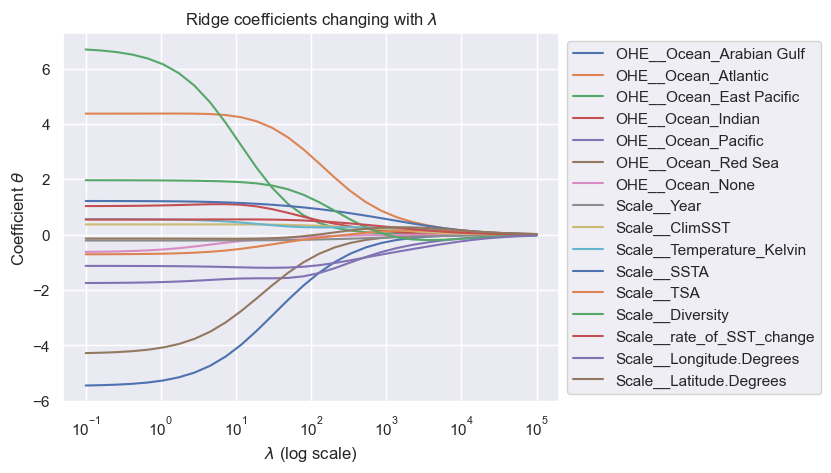

In [49]:
plt.plot(alphas, coeffs_ridge_ohe, label=coefficient_names)
plt.xlabel(r'$\lambda$ (log scale)')
plt.ylabel(r'Coefficient $\theta$')
plt.semilogx()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5));
plt.title(r'Ridge coefficients changing with $\lambda$');

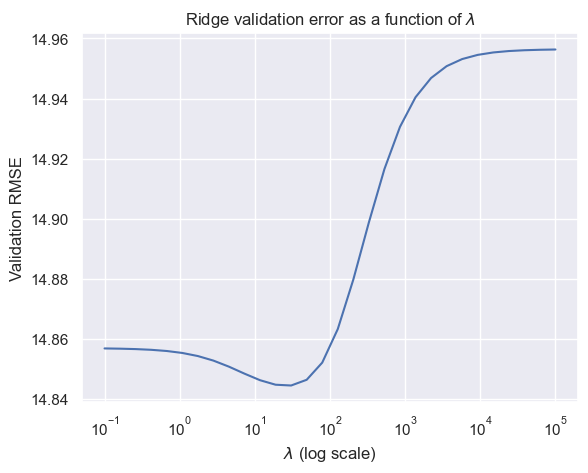

In [50]:
plt.plot(alphas, ridge_val_errors)
plt.title('Ridge validation error as a function of $\lambda$')
plt.xlabel(r'$\lambda$ (log scale)')
plt.ylabel(r'Validation RMSE');
plt.semilogx();

Bonus question: How would you improve the last two coefficient visualizations to better communicate their intended message?